Mounts Google Drive to access the downloaded SFDD and AUC-DDD zip files.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Extracts dataset directly into Colab's fast local storage to prevent IO bottlenecks during training.



In [4]:
!mkdir -p /content/dataset
!unzip -qo "/content/drive/MyDrive/state-farm-distracted-driver-detection.zip" -d /content/dataset/

print("Data ready")

Data ready


Imports required libraries (including KerasCV for the Vision Transformer) and configures the data loading pipelines with data augmentation for generalization.

In [6]:
!pip install -q keras_cv tensorflow tensorflow_hub

import os
import time
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
import keras_cv
from sklearn.metrics import accuracy_score, log_loss, f1_score, confusion_matrix, roc_auc_score


# Training and Validation Sets (SFDD)
train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/state-farm-distracted-driver-detection/imgs/train', validation_split=0.2, subset="training",
    seed=123, image_size=(224, 224), batch_size=32, label_mode='categorical'
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/state-farm-distracted-driver-detection/imgs/train', validation_split=0.2, subset="validation",
    seed=123, image_size=(224, 224), batch_size=32, label_mode='categorical'
)


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Found 22424 files belonging to 10 classes.
Using 17940 files for training.
Found 22424 files belonging to 10 classes.
Using 4484 files for validation.


Defines a reusable function to extract all required radar chart metrics (Accuracy, Log Loss, F1, AUC, Parameters, Size, Latency, FPS, and FPR) directly from saved weights.

In [11]:
def evaluate_saved_model(model_file_path):
    print(f"\n--- EVALUATING: {model_file_path} ---")

    model = tf.keras.models.load_model(model_file_path, safe_mode=False)

    y_true, y_pred = [], []
    for images, labels in val_ds:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_true_classes = np.argmax(y_true, axis=1)
    y_pred_classes = np.argmax(y_pred, axis=1)

    print("\n1. CLASSIFICATION QUALITY")
    print(f"Top-1 Accuracy: {accuracy_score(y_true_classes, y_pred_classes):.4f}")
    print(f"Log Loss: {log_loss(y_true_classes, y_pred, labels=[0,1,2,3,4,5,6,7,8,9]):.4f}")
    print(f"F1-Score (Macro): {f1_score(y_true_classes, y_pred_classes, average='macro'):.4f}")
    print(f"Multiclass OvR AUC: {roc_auc_score(y_true, y_pred, multi_class='ovr', average='macro'):.4f}")

    print("\n2. MODEL COMPLEXITY")
    print(f"Total Parameters: {model.count_params() / 1e6:.2f} M")
    print(f"Model Size: {os.path.getsize(model_file_path) / (1024 * 1024):.2f} MB")

    print("\n3. RUNTIME PERFORMANCE")
    dummy = np.random.rand(1, 224, 224, 3).astype(np.float32)
    _ = model.predict(dummy, verbose=0) # Warmup

    start = time.time()
    for _ in range(100):
        _ = model.predict(dummy, verbose=0)
    latency_ms = ((time.time() - start) / 100) * 1000
    print(f"Latency per frame: {latency_ms:.2f} ms")
    print(f"Throughput: {1000 / latency_ms:.2f} FPS")

    print("\n4. TEMPORAL STABILITY")
    def sliding_window_voting(preds, window=15):
        return [np.bincount(preds[max(0, i-window+1):i+1]).argmax() for i in range(len(preds))]

    y_pred_smoothed = np.array(sliding_window_voting(y_pred_classes))
    true_safe = (y_true_classes == 0)
    pred_distracted = (y_pred_smoothed != 0)
    if np.sum(true_safe) > 0:
        print(f"FPR (N=15): {np.sum(true_safe & pred_distracted) / np.sum(true_safe):.4f}")

Builds and trains a standard Convolutional Neural Network from scratch to establish baseline metrics.

In [ ]:

# 1. Augmentation & Callbacks
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2)
], name="augmentation_layer")

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

# 2. Build the CNN
inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x) # Custom CNNs need manual scaling

x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x) # High dropout to prevent overfitting
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_cnn = models.Model(inputs, outputs)
model_cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])

# 3. Train & Save
model_cnn.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=[early_stopping, reduce_lr])

model_cnn.save('/content/drive/MyDrive/Custom_CNN_SFDD_Optimized.keras')
evaluate_saved_model('/content/drive/MyDrive/Custom_CNN_SFDD_Optimized.keras')

Epoch 1/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 55s 85ms/step - accuracy: 0.5108 - loss: 1.4068 - val_accuracy: 0.8022 - val_loss: 0.6168 - learning_rate: 0.0010
Epoch 2/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 76s 83ms/step - accuracy: 0.8220 - loss: 0.5520 - val_accuracy: 0.9161 - val_loss: 0.2717 - learning_rate: 0.0010
Epoch 3/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.8958 - loss: 0.3395 - val_accuracy: 0.9302 - val_loss: 0.2208 - learning_rate: 0.0010
Epoch 4/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 44s 79ms/step - accuracy: 0.9215 - loss: 0.2487 - val_accuracy: 0.9607 - val_loss: 0.1461 - learning_rate: 0.0010
Epoch 5/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 82s 79ms/step - accuracy: 0.9367 - loss: 0.2029 - val_accuracy: 0.9614 - val_loss: 0.1365 - learning_rate: 0.0010
Epoch 6/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 82s 79ms/step - accuracy: 0.9475 - loss: 0.1688 - val_accuracy: 0.9679 - val_loss: 0.1136 - learning_rate: 0.0010
Epoch 7/50
561/561 ━━━━━━━━━━━━━━━━━━━━ 48s 85ms/step - accuracy: 0.9567 - l

Implements transfer learning using MobileNetV2, an architecture optimized for high-speed edge devices.

In [ ]:


# 1. Aggressive Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),      # Slight tilting
    layers.RandomBrightness(0.2),    # Handles different lighting
    layers.RandomContrast(0.2)       # Handles glare and shadows
], name="augmentation_layer")

# 2. Setup the Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=6,                     # Stop if no improvement for 6 epochs
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,                     # Cut learning rate in half
    patience=3,
    min_lr=1e-6
)

# 3. Build the Base Model (PHASE 1)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


# Increased to 30 epochs, but EarlyStopping will likely catch it earlier
history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping, reduce_lr]
)

# 4. Fine-Tuning

base_model.trainable = True

# Freeze the first 100 layers, unfreeze the rest
for layer in base_model.layers[:100]:
    layer.trainable = False

# Recompile with a drastically lower learning rate (1e-5 instead of 1e-3)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train again for another 20 epochs
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping, reduce_lr]
)

# Save the fully optimized model
model.save('/content/drive/MyDrive/MobileNetV2_SFDD_Optimized.keras')
evaluate_saved_model('/content/drive/MyDrive/MobileNetV2_SFDD_Optimized.keras')

Epoch 1/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.4618 - loss: 1.5838 - val_accuracy: 0.6610 - val_loss: 1.0812 - learning_rate: 0.0010
Epoch 2/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 79s 82ms/step - accuracy: 0.6571 - loss: 1.0352 - val_accuracy: 0.7174 - val_loss: 0.8992 - learning_rate: 0.0010
Epoch 3/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 47s 84ms/step - accuracy: 0.6976 - loss: 0.9117 - val_accuracy: 0.7723 - val_loss: 0.7582 - learning_rate: 0.0010
Epoch 4/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 46s 81ms/step - accuracy: 0.7140 - loss: 0.8528 - val_accuracy: 0.7632 - val_loss: 0.7614 - learning_rate: 0.0010
Epoch 5/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 49s 87ms/step - accuracy: 0.7229 - loss: 0.8199 - val_accuracy: 0.8022 - val_loss: 0.6477 - learning_rate: 0.0010
Epoch 6/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 82s 86ms/step - accuracy: 0.7356 - loss: 0.7952 - val_accuracy: 0.7881 - val_loss: 0.6590 - learning_rate: 0.0010
Epoch 7/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 83s 89ms/step - accuracy: 0.7321 - l

Implements transfer learning using ResNet50, a deeper architecture designed to eliminate vanishing gradients.

In [ ]:


data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2)
], name="augmentation_layer")

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)


# 1. Base Model (PHASE 1)
resnet_base = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
resnet_base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = resnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_resnet = models.Model(inputs, outputs)
model_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                     loss='categorical_crossentropy', metrics=['accuracy'])

model_resnet.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stopping, reduce_lr])

# 2. Fine-Tuning (PHASE 2)
resnet_base.trainable = True

for layer in resnet_base.layers[:140]:
    layer.trainable = False

model_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                     loss='categorical_crossentropy', metrics=['accuracy'])

model_resnet.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stopping, reduce_lr])

model_resnet.save('/content/drive/MyDrive/ResNet50_SFDD_Optimized.keras')
evaluate_saved_model('/content/drive/MyDrive/ResNet50_SFDD_Optimized.keras')

Epoch 1/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 111s 183ms/step - accuracy: 0.5069 - loss: 1.4722 - val_accuracy: 0.8104 - val_loss: 0.6718 - learning_rate: 0.0010
Epoch 2/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 138s 177ms/step - accuracy: 0.7114 - loss: 0.8601 - val_accuracy: 0.8512 - val_loss: 0.5083 - learning_rate: 0.0010
Epoch 3/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 142s 178ms/step - accuracy: 0.7479 - loss: 0.7471 - val_accuracy: 0.7966 - val_loss: 0.6004 - learning_rate: 0.0010
Epoch 4/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 100s 178ms/step - accuracy: 0.7736 - loss: 0.6744 - val_accuracy: 0.8410 - val_loss: 0.4920 - learning_rate: 0.0010
Epoch 5/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 100s 178ms/step - accuracy: 0.7822 - loss: 0.6438 - val_accuracy: 0.8901 - val_loss: 0.3672 - learning_rate: 0.0010
Epoch 6/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 143s 180ms/step - accuracy: 0.7875 - loss: 0.6228 - val_accuracy: 0.8628 - val_loss: 0.4261 - learning_rate: 0.0010
Epoch 7/30
561/561 ━━━━━━━━━━━━━━━━━━━━ 99s 176ms/step - accurac

Implements a Vision Transformer (ViT) backbone, utilizing attention mechanisms rather than spatial convolutions.

In [10]:
import tensorflow_hub as hub
from tensorflow.keras import layers, models
import tensorflow as tf

# 1. Download the ViT model and get its local system path
vit_url = "https://tfhub.dev/sayakpaul/vit_b16_fe/1"
model_path = hub.resolve(vit_url)

# 2. Use Keras 3's native layer for loading SavedModels
vit_base = layers.TFSMLayer(model_path, call_endpoint='serving_default')

# Freeze the imported layer to prevent the optimizer naming crash
vit_base.trainable = False

# 3. Build the model using the Functional API
inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)

# Pass the augmented images through the Vision Transformer
vit_outputs = vit_base(x)

# TFSMLayer outputs a dictionary of tensors. We use flatten to safely grab the 768-dimension feature vector.
vit_features = tf.nest.flatten(vit_outputs)[0]

# Add our custom 10-class State Farm prediction head
outputs = layers.Dense(10, activation='softmax')(vit_features)

# Compile the final model
model_vit = models.Model(inputs=inputs, outputs=outputs)
model_vit.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Train, Save, and Evaluate
print("Training Vision Transformer (ViT)...")
model_vit.fit(train_ds, validation_data=val_ds, epochs=5)

model_vit.save('/content/drive/MyDrive/ViT_SFDD.keras')
evaluate_saved_model('/content/drive/MyDrive/ViT_SFDD.keras')

Training Vision Transformer (ViT)...
Epoch 1/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 327s 558ms/step - accuracy: 0.1396 - loss: 2.3956 - val_accuracy: 0.1579 - val_loss: 2.3044
Epoch 2/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 310s 553ms/step - accuracy: 0.1879 - loss: 2.2518 - val_accuracy: 0.2021 - val_loss: 2.2297
Epoch 3/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 310s 553ms/step - accuracy: 0.2179 - loss: 2.1762 - val_accuracy: 0.2172 - val_loss: 2.1471
Epoch 4/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 310s 552ms/step - accuracy: 0.2421 - loss: 2.1344 - val_accuracy: 0.2627 - val_loss: 2.0800
Epoch 5/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 310s 553ms/step - accuracy: 0.2444 - loss: 2.1223 - val_accuracy: 0.2360 - val_loss: 2.0880


NameError: name 'evaluate_saved_model' is not defined

In [12]:
evaluate_saved_model('/content/drive/MyDrive/ViT_SFDD.keras')


--- EVALUATING: /content/drive/MyDrive/ViT_SFDD.keras ---

1. CLASSIFICATION QUALITY
Top-1 Accuracy: 0.2360
Log Loss: 2.0880
F1-Score (Macro): 0.1775
Multiclass OvR AUC: 0.7522

2. MODEL COMPLEXITY
Total Parameters: 85.81 M
Model Size: 327.48 MB

3. RUNTIME PERFORMANCE
Latency per frame: 109.71 ms
Throughput: 9.11 FPS

4. TEMPORAL STABILITY
FPR (N=15): 1.0000


In [13]:
evaluate_saved_model('/content/drive/MyDrive/ResNet50_SFDD_Optimized.keras')


--- EVALUATING: /content/drive/MyDrive/ResNet50_SFDD_Optimized.keras ---

1. CLASSIFICATION QUALITY
Top-1 Accuracy: 0.9953
Log Loss: 0.0222
F1-Score (Macro): 0.9952
Multiclass OvR AUC: 0.9998

2. MODEL COMPLEXITY
Total Parameters: 23.61 M
Model Size: 205.16 MB

3. RUNTIME PERFORMANCE
Latency per frame: 103.81 ms
Throughput: 9.63 FPS

4. TEMPORAL STABILITY
FPR (N=15): 0.6484


In [14]:
evaluate_saved_model('/content/drive/MyDrive/MobileNetV2_SFDD_Optimized.keras')


--- EVALUATING: /content/drive/MyDrive/MobileNetV2_SFDD_Optimized.keras ---

1. CLASSIFICATION QUALITY
Top-1 Accuracy: 0.9915
Log Loss: 0.0339
F1-Score (Macro): 0.9914
Multiclass OvR AUC: 0.9997

2. MODEL COMPLEXITY
Total Parameters: 2.27 M
Model Size: 23.57 MB

3. RUNTIME PERFORMANCE
Latency per frame: 87.43 ms
Throughput: 11.44 FPS

4. TEMPORAL STABILITY
FPR (N=15): 0.6462


In [15]:
evaluate_saved_model('/content/drive/MyDrive/Custom_CNN_SFDD_Optimized.keras')


--- EVALUATING: /content/drive/MyDrive/Custom_CNN_SFDD_Optimized.keras ---

1. CLASSIFICATION QUALITY
Top-1 Accuracy: 0.9931
Log Loss: 0.0304
F1-Score (Macro): 0.9929
Multiclass OvR AUC: 0.9999

2. MODEL COMPLEXITY
Total Parameters: 11.17 M
Model Size: 127.89 MB

3. RUNTIME PERFORMANCE
Latency per frame: 92.29 ms
Throughput: 10.84 FPS

4. TEMPORAL STABILITY
FPR (N=15): 0.6176


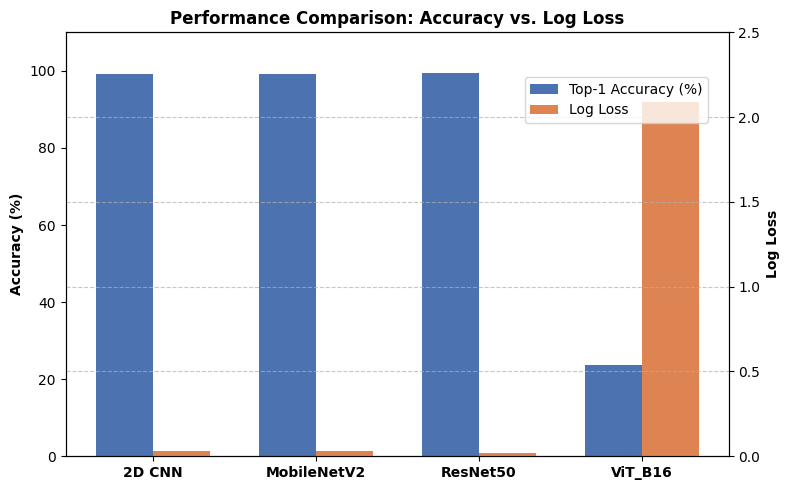

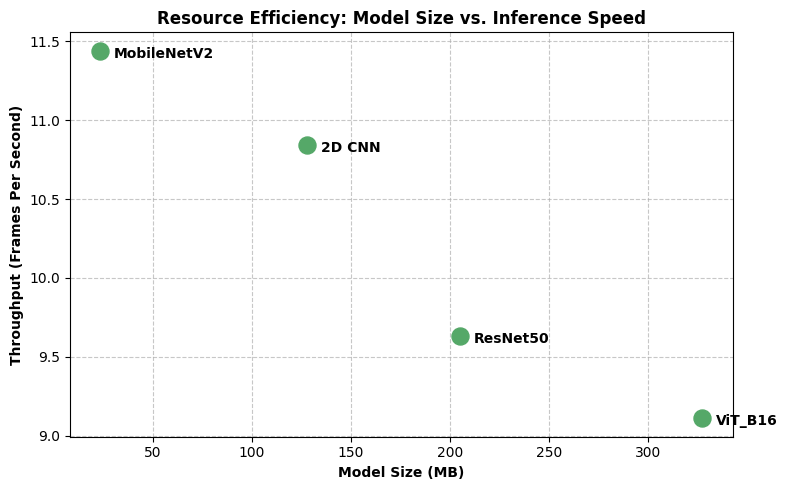

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your report[cite: 9]
models = ['2D CNN', 'MobileNetV2', 'ResNet50', 'ViT_B16']
accuracy = [99.31, 99.15, 99.53, 23.60]
log_loss = [0.0304, 0.0339, 0.0222, 2.0880]
model_size_mb = [127.89, 23.57, 205.16, 327.48]
fps = [10.84, 11.44, 9.63, 9.11]

# ---------------------------------------------------------
# FIGURE 1: Comparative Bar Chart (Accuracy & Log Loss)
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(8, 5))

x = np.arange(len(models))
width = 0.35

# Plot Accuracy on primary Y-axis
bars1 = ax1.bar(x - width/2, accuracy, width, label='Top-1 Accuracy (%)', color='#4C72B0')
ax1.set_ylabel('Accuracy (%)', fontweight='bold')
ax1.set_ylim(0, 110)
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontweight='bold')

# Plot Log Loss on secondary Y-axis
ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, log_loss, width, label='Log Loss', color='#DD8452')
ax2.set_ylabel('Log Loss', fontweight='bold')
ax2.set_ylim(0, 2.5)

# Add legends and title
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))
plt.title('Performance Comparison: Accuracy vs. Log Loss', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save Figure 1
plt.savefig('accuracy_loss_chart.png', dpi=300)
plt.show()

# ---------------------------------------------------------
# FIGURE 2: Resource Efficiency Graph (Size vs Throughput)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))

# Create a scatter plot for Size vs FPS
plt.scatter(model_size_mb, fps, color='#55A868', s=150, zorder=5)

# Annotate each point with the model name
for i, model in enumerate(models):
    plt.annotate(model, (model_size_mb[i], fps[i]),
                 xytext=(10, -5), textcoords='offset points',
                 fontweight='bold', fontsize=10)

plt.title('Resource Efficiency: Model Size vs. Inference Speed', fontweight='bold')
plt.xlabel('Model Size (MB)', fontweight='bold')
plt.ylabel('Throughput (Frames Per Second)', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Save Figure 2
plt.savefig('efficiency_chart.png', dpi=300)
plt.show()

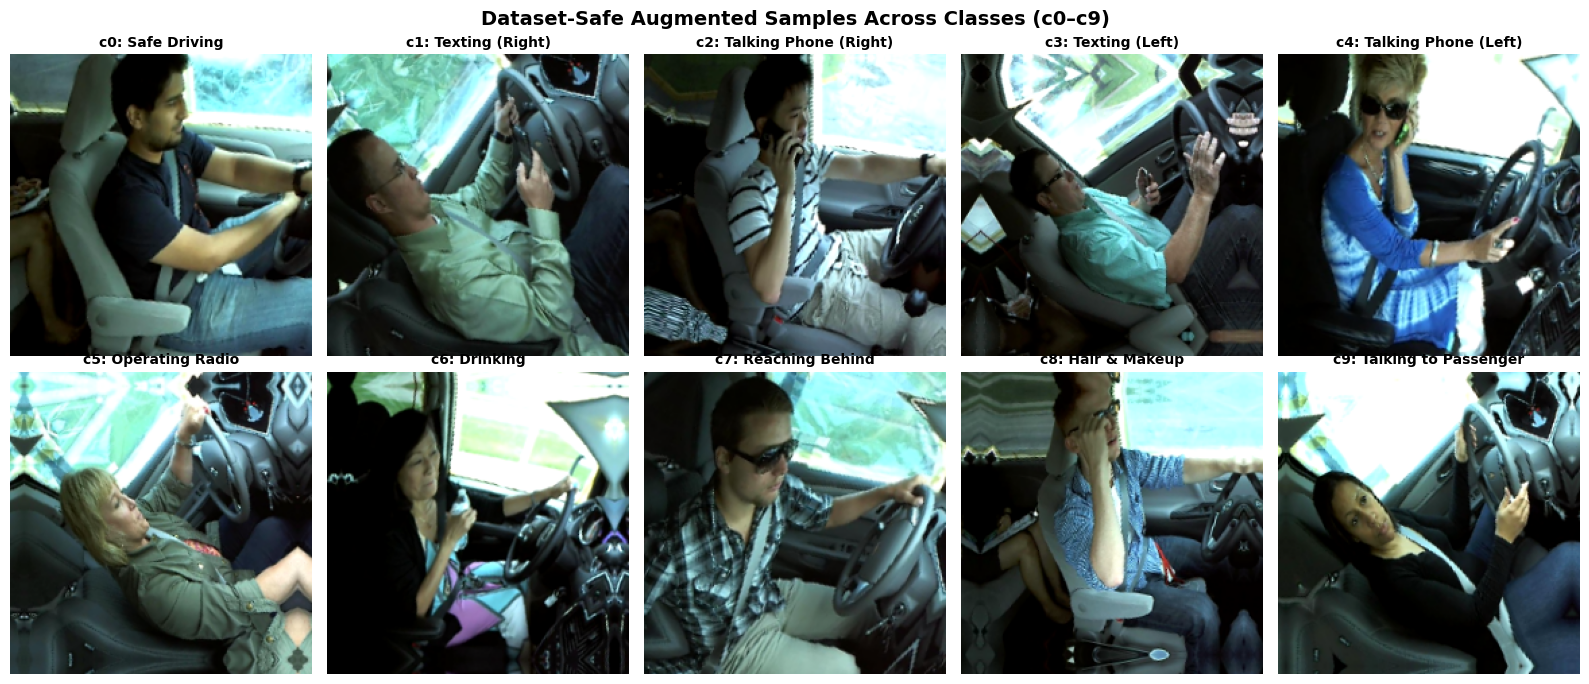

In [9]:
import os
import random
import tensorflow as tf
import matplotlib.pyplot as plt

# Update this path to your training directory containing c0 through c9 folders
train_dir = '/content/dataset/state-farm-distracted-driver-detection/imgs/train'

class_labels = [
    'c0: Safe Driving',
    'c1: Texting (Right)',
    'c2: Talking Phone (Right)',
    'c3: Texting (Left)',
    'c4: Talking Phone (Left)',
    'c5: Operating Radio',
    'c6: Drinking',
    'c7: Reaching Behind',
    'c8: Hair & Makeup',
    'c9: Talking to Passenger'
]

# Your dataset-safe augmentation pipeline (no horizontal flips)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15)
])

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for idx in range(10):
    class_folder = os.path.join(train_dir, f'c{idx}')
    sample_img_name = random.choice(os.listdir(class_folder))
    img_path = os.path.join(class_folder, sample_img_name)

    # Load and resize image to 224x224
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)

    # Apply augmentation (expects a batch dimension)
    aug_img = data_augmentation(tf.expand_dims(img_array, 0), training=True)[0]
    aug_img = tf.clip_by_value(aug_img, 0, 255).numpy().astype("uint8")

    axes[idx].imshow(aug_img)
    axes[idx].set_title(class_labels[idx], fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Dataset-Safe Augmented Samples Across Classes (c0–c9)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('augmented_grid.png', dpi=300, bbox_inches='tight')
plt.show()